# NLP Sentiment Classification on Movie Reviews (TF-IDF)

**Machine Learning & Data Science Internship Task 4**

Build a text classifier that labels a movie review as **positive** or **negative**.

**Workflow**
1. Load 20,000 IMDB movie reviews (balanced: 10,000 positive, 10,000 negative)
2. EDA: class balance, review lengths, raw text problems (HTML tags, punctuation)
3. Text preprocessing with regex and NLTK: lowercasing, HTML / URL / punctuation removal, stopword removal
   (keeping negations), lemmatisation
4. Convert text into numbers with `TfidfVectorizer(max_features=5000)`
5. Train **Multinomial Naive Bayes** and **Logistic Regression**
6. Benchmark accuracy, precision, recall, F1 and ROC-AUC on a held-out test set, plus 5-fold cross-validation
7. Inspect the most informative words for each model
8. A `predict_sentiment()` helper that classifies any custom sentence

## 1. Setup and imports

In [1]:
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
    classification_report, confusion_matrix,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# Download the NLTK resources only if they are not installed yet
for resource, path in [("stopwords", "corpora/stopwords"), ("wordnet", "corpora/wordnet"), ("omw-1.4", "corpora/omw-1.4")]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(resource, quiet=True)

## 2. Load the dataset

The source is the well-known **IMDB Dataset of 50K Movie Reviews** (Maas et al., 2011, Stanford). To keep the
repository small and the notebook quick to run, `../data/imdb_reviews_20k.csv.gz` holds a **balanced random sample
of 20,000 reviews** (duplicates removed, `random_state=42`). Pandas reads the gzip file directly. If the file is
missing, the notebook rebuilds the same sample from the full public CSV.

In [2]:
DATA_PATH = Path("../data/imdb_reviews_20k.csv.gz")
FULL_DATA_URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    full = pd.read_csv(FULL_DATA_URL).drop_duplicates()
    df = (full.groupby("sentiment", group_keys=False).sample(n=10_000, random_state=RANDOM_STATE)
              .sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True))

print(f"Shape: {df.shape[0]:,} reviews x {df.shape[1]} columns")
df.head()

Shape: 20,000 reviews x 2 columns


,review,sentiment
0,I went into this expecting not to like it; I f...,positive
1,Couple having financial trouble gets a box del...,negative
2,An anonymous film which could have been direct...,negative
3,"Rita Hayworth is just stunning at times and, f...",negative
4,Is this the future that awaits us? An overpopu...,positive


## 3. Exploratory data analysis

In [3]:
print(df["sentiment"].value_counts())
print("\nMissing values:", df.isnull().sum().sum())

df["n_words"] = df["review"].str.split().str.len()
df["has_html"] = df["review"].str.contains(r"<[^>]+>", regex=True)
print(f"Reviews containing HTML tags: {df['has_html'].mean():.1%}")
df.groupby("sentiment")["n_words"].describe().round(1)

sentiment
positive    10000
negative    10000
Name: count, dtype: int64

Missing values: 0


Reviews containing HTML tags: 58.6%


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,10000.0,229.3,165.2,4.0,128.0,175.0,279.0,1475.0
positive,10000.0,234.9,179.8,10.0,125.0,174.0,287.0,2470.0


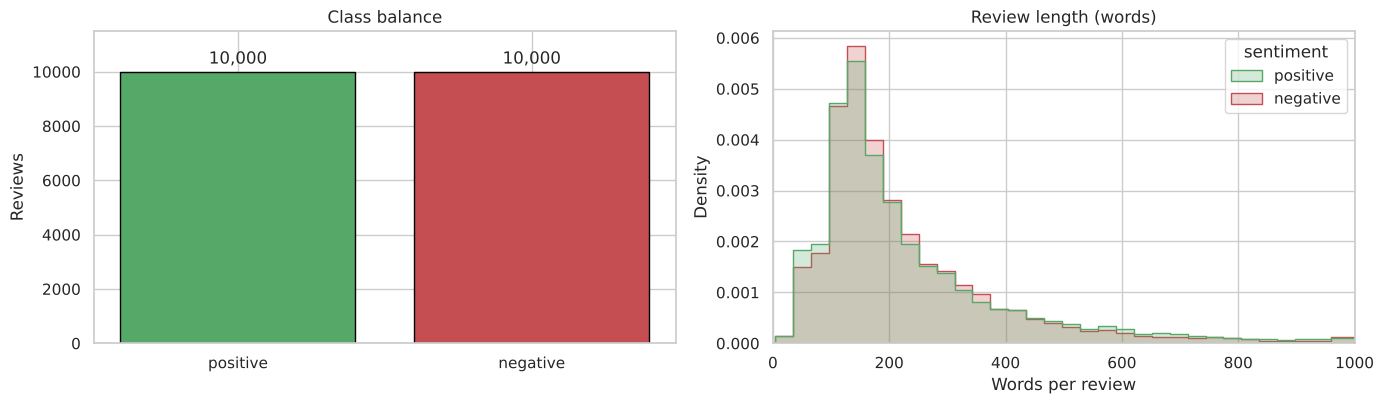

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
counts = df["sentiment"].value_counts()
bars = axes[0].bar(counts.index, counts.values, color=["#C44E52", "#55A868"] if counts.index[0] == "negative" else ["#55A868", "#C44E52"],
                   edgecolor="black")
axes[0].bar_label(bars, fmt="{:,.0f}", padding=3)
axes[0].set_title("Class balance")
axes[0].set_ylabel("Reviews")
axes[0].set_ylim(0, counts.max() * 1.15)

sns.histplot(data=df, x="n_words", hue="sentiment", bins=80, element="step", stat="density",
             common_norm=False, palette={"positive": "#55A868", "negative": "#C44E52"}, ax=axes[1])
axes[1].set_xlim(0, 1000)
axes[1].set_title("Review length (words)")
axes[1].set_xlabel("Words per review")
plt.tight_layout()
plt.show()

The classes are perfectly balanced, so accuracy is a fair headline metric. Positive and negative reviews have
very similar length distributions (median about 170 words), so length alone says little about sentiment; the
words themselves must do the work.

In [5]:
# A raw example: note the HTML line breaks, capitals and punctuation
example = df.loc[df["has_html"], "review"].iloc[0]
print(example[:700])

I went into this expecting not to like it; I figured it would be terribly worthy and earnest, and rather plodding and dull.<br /><br />It's actually far better than that, and I found myself really enjoying it. I don't know too much about Queen Victoria beyond what most know - married to Albert, who died young, and she mourned him ever after. Seeing the circumstances she grew up under was fascinating; in fact I found myself wishing I'd seen more of the story, and I imagine we may see a sequel at some point.<br /><br />Visually the film is stunning. The sets and costumes are incredibly lavish without being too gaudy and over the top. The acting is top notch from everybody involved.<br /><br />


## 4. Text preprocessing

Steps applied to every review:

1. **Lowercase** everything
2. Remove **HTML tags** (e.g. `<br />`) and **URLs**
3. Expand **negative contractions** (`don't` → `do not`) so the negation survives punctuation removal
4. Remove **punctuation, digits and other non-letters**
5. Remove **stopwords** (very common words such as *the*, *and*, *is*), but **keep negation words** such as
   *not*, *no* and *never*, because they flip sentiment ("not good")
6. **Lemmatise** each word to its dictionary form (*movies* → *movie*, *was* stays *was*), using WordNet

In [6]:
NEGATIONS = {"no", "not", "nor", "never", "none", "nobody", "nothing", "neither", "nowhere"}
STOPWORDS = set(stopwords.words("english")) - NEGATIONS
lemmatizer = WordNetLemmatizer()

HTML_RE = re.compile(r"<[^>]+>")
URL_RE = re.compile(r"https?://\S+|www\.\S+")
NOT_RE = re.compile(r"n't\b")
NON_LETTER_RE = re.compile(r"[^a-z\s]")


def clean_text(text: str) -> str:
    """Lowercase, strip HTML/URLs/punctuation, drop stopwords (keeping negations) and lemmatise."""
    text = text.lower()
    text = HTML_RE.sub(" ", text)
    text = URL_RE.sub(" ", text)
    text = text.replace("can't", "can not").replace("won't", "will not")
    text = NOT_RE.sub(" not", text)
    text = NON_LETTER_RE.sub(" ", text)
    tokens = [lemmatizer.lemmatize(tok) for tok in text.split() if tok not in STOPWORDS and len(tok) > 1]
    return " ".join(tokens)


# Before / after on a short example
sample = "I didn't like this movie at all!<br /><br />The acting was TERRIBLE and the plot made no sense... 2/10"
print("Before:", sample)
print("After: ", clean_text(sample))

Before: I didn't like this movie at all!<br /><br />The acting was TERRIBLE and the plot made no sense... 2/10


After:  not like movie acting terrible plot made no sense


In [7]:
start = time.perf_counter()
df["clean_review"] = df["review"].apply(clean_text)
print(f"Cleaned {len(df):,} reviews in {time.perf_counter() - start:.1f} s")

df["clean_words"] = df["clean_review"].str.split().str.len()
print(f"Average words per review: {df['n_words'].mean():.0f} before -> {df['clean_words'].mean():.0f} after cleaning")
df[["review", "clean_review"]].head(3)

Cleaned 20,000 reviews in 6.7 s


Average words per review: 232 before -> 122 after cleaning


,review,clean_review
0,I went into this expecting not to like it; I f...,went expecting not like figured would terribly...
1,Couple having financial trouble gets a box del...,couple financial trouble get box delivered doo...
2,An anonymous film which could have been direct...,anonymous film could directed anyone anthony m...


### 4.1 Most frequent words per class (after cleaning)

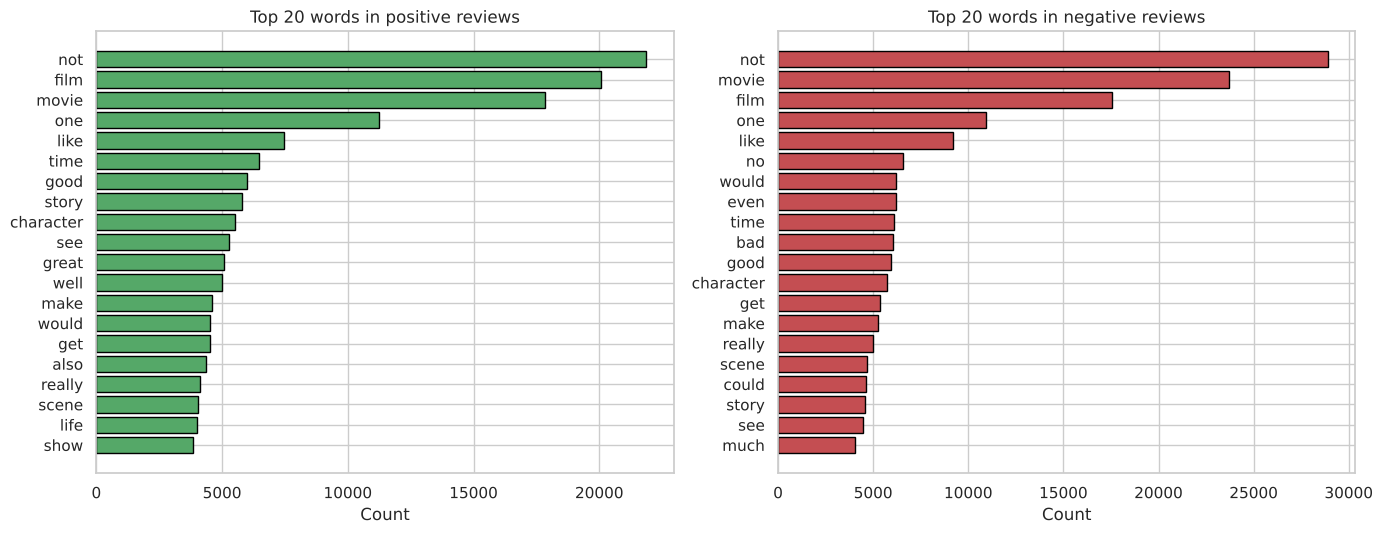

In [8]:
from collections import Counter

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (label, color) in zip(axes, [("positive", "#55A868"), ("negative", "#C44E52")]):
    words = Counter(" ".join(df.loc[df["sentiment"] == label, "clean_review"]).split())
    top = pd.Series(dict(words.most_common(20))).sort_values()
    ax.barh(top.index, top.values, color=color, edgecolor="black")
    ax.set_title(f"Top 20 words in {label} reviews")
    ax.set_xlabel("Count")
plt.tight_layout()
plt.show()

Raw frequency is dominated by words that appear in *every* review (*movie*, *film*, *one*). This is exactly the
problem TF-IDF solves: it down-weights words that are common across all documents and up-weights words that are
distinctive, such as *great*, *bad* or *worst*.

## 5. Train/test split and TF-IDF features

- **Stratified 80/20 split** (16,000 training and 4,000 test reviews).
- `TfidfVectorizer(max_features=5000)` keeps the 5,000 most frequent terms. We also use `ngram_range=(1, 2)`, so
  two-word phrases such as *not good* or *waste time* can be selected as features alongside single words.
- The vectorizer is **fitted on the training reviews only** and then applied to the test reviews.

In [9]:
X = df["clean_review"]
y = (df["sentiment"] == "positive").astype(int)        # 1 = positive, 0 = negative

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"Training matrix: {X_train_tfidf.shape[0]:,} reviews x {X_train_tfidf.shape[1]:,} features")
print(f"Test matrix:     {X_test_tfidf.shape[0]:,} reviews x {X_test_tfidf.shape[1]:,} features")
print(f"Sparsity: {1 - X_train_tfidf.nnz / np.prod(X_train_tfidf.shape):.2%} of the matrix is zero")

bigrams = [t for t in vectorizer.get_feature_names_out() if " " in t]
print(f"\n{len(bigrams)} of the 5,000 features are two-word phrases, e.g.:", bigrams[:12])

Training matrix: 16,000 reviews x 5,000 features
Test matrix:     4,000 reviews x 5,000 features
Sparsity: 98.27% of the matrix is zero

1040 of the 5,000 features are two-word phrases, e.g.: ['absolutely no', 'absolutely nothing', 'academy award', 'act like', 'acting ability', 'acting bad', 'acting good', 'acting not', 'action film', 'action movie', 'action scene', 'action sequence']


## 6. Model training

In [10]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, C=1.0, random_state=RANDOM_STATE),
}

train_times = {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train_tfidf, y_train)
    train_times[name] = time.perf_counter() - start
    print(f"{name}: trained in {train_times[name]:.3f} s")

Multinomial Naive Bayes: trained in 0.012 s
Logistic Regression: trained in 0.062 s


## 7. Accuracy benchmarks

In [11]:
rows, preds, probas = [], {}, {}
for name, model in models.items():
    preds[name] = model.predict(X_test_tfidf)
    probas[name] = model.predict_proba(X_test_tfidf)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name]),
        "Recall": recall_score(y_test, preds[name]),
        "F1-score": f1_score(y_test, preds[name]),
        "ROC-AUC": roc_auc_score(y_test, probas[name]),
        "Train time (s)": train_times[name],
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Train time (s)
Model,,,,,,
Multinomial Naive Bayes,0.8620,0.8657,0.8570,0.8613,0.9414,0.0118
Logistic Regression,0.8938,0.8900,0.8985,0.8943,0.9617,0.0622


In [12]:
for name in models:
    print("=" * 60)
    print(f"Classification report: {name}")
    print("=" * 60)
    print(classification_report(y_test, preds[name], target_names=["negative", "positive"], digits=4))

Classification report: Multinomial Naive Bayes
              precision    recall  f1-score   support

    negative     0.8584    0.8670    0.8627      2000
    positive     0.8657    0.8570    0.8613      2000

    accuracy                         0.8620      4000
   macro avg     0.8620    0.8620    0.8620      4000
weighted avg     0.8620    0.8620    0.8620      4000

Classification report: Logistic Regression
              precision    recall  f1-score   support

    negative     0.8975    0.8890    0.8932      2000
    positive     0.8900    0.8985    0.8943      2000

    accuracy                         0.8938      4000
   macro avg     0.8938    0.8938    0.8937      4000
weighted avg     0.8938    0.8938    0.8937      4000



### 7.1 Cross-validation

A single split can be lucky or unlucky, so we also run **5-fold stratified cross-validation** on the training set.
The vectorizer goes inside a pipeline so it is re-fitted on each training fold (no leakage).

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    pipe = make_pipeline(TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True), model)
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    cv_rows.append({"Model": name, "CV accuracy mean": scores.mean(), "CV accuracy std": scores.std(),
                    "Fold scores": np.round(scores, 4).tolist()})
cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.round(4)

,CV accuracy mean,CV accuracy std,Fold scores
Model,,,
Multinomial Naive Bayes,0.8557,0.0052,"[0.8519, 0.8588, 0.8494, 0.8641, 0.8547]"
Logistic Regression,0.8821,0.0026,"[0.8838, 0.8788, 0.8809, 0.8809, 0.8862]"


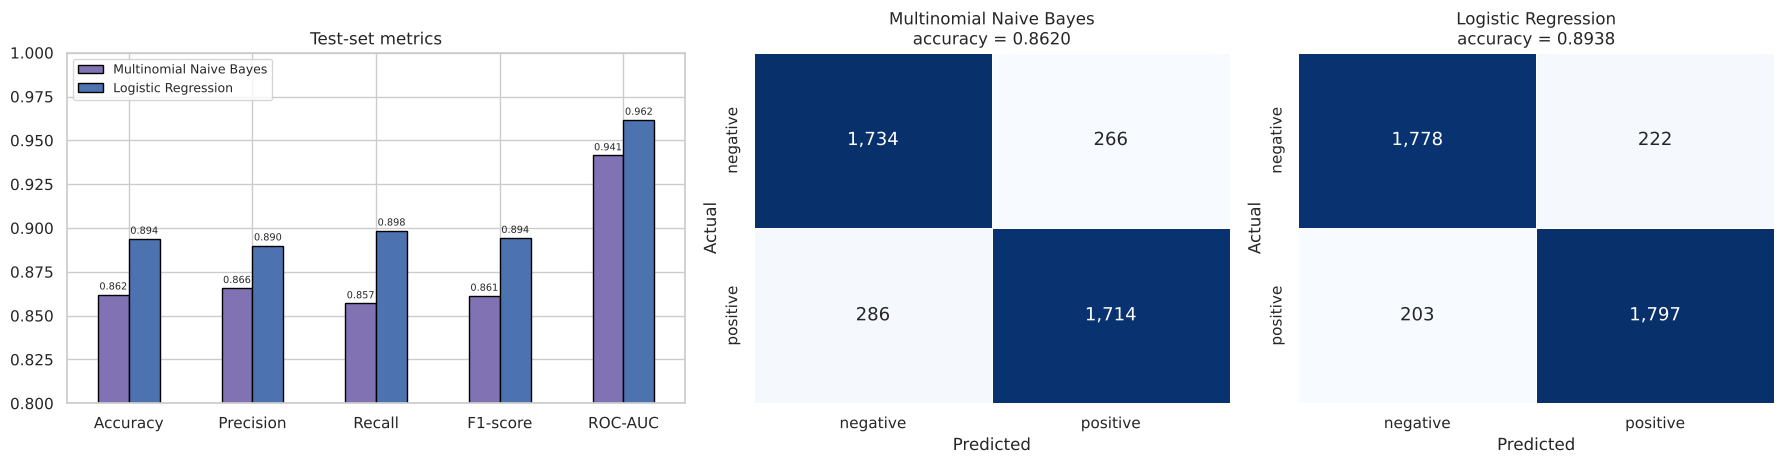

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
colors = {"Multinomial Naive Bayes": "#8172B3", "Logistic Regression": "#4C72B0"}

# Metric comparison
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
results[metric_cols].T.plot(kind="bar", ax=axes[0], color=[colors[m] for m in results.index], edgecolor="black")
axes[0].set_ylim(0.8, 1.0)
axes[0].set_title("Test-set metrics")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(loc="upper left", fontsize=9)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=7, padding=2)

# Confusion matrices
for ax, name in zip(axes[1:], models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["negative", "positive"], yticklabels=["negative", "positive"],
                annot_kws={"size": 13}, linewidths=0.5, linecolor="white")
    ax.set_title(f"{name}\naccuracy = {accuracy_score(y_test, preds[name]):.4f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

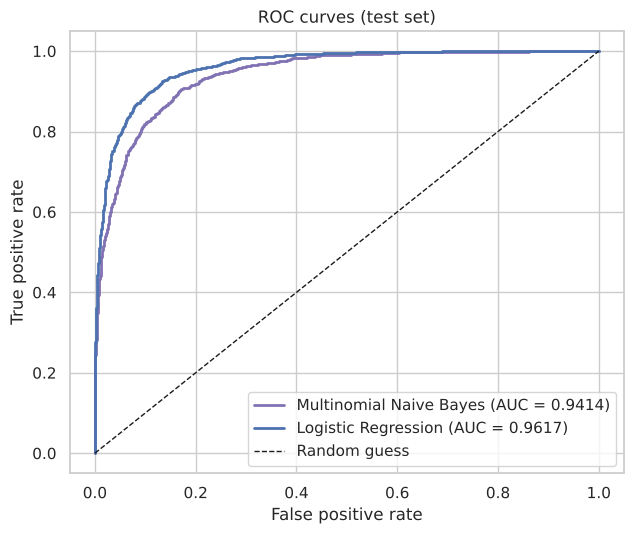

In [15]:
plt.figure(figsize=(6.5, 5.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, lw=2, color=colors[name], label=f"{name} (AUC = {roc_auc_score(y_test, probas[name]):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves (test set)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Most informative words

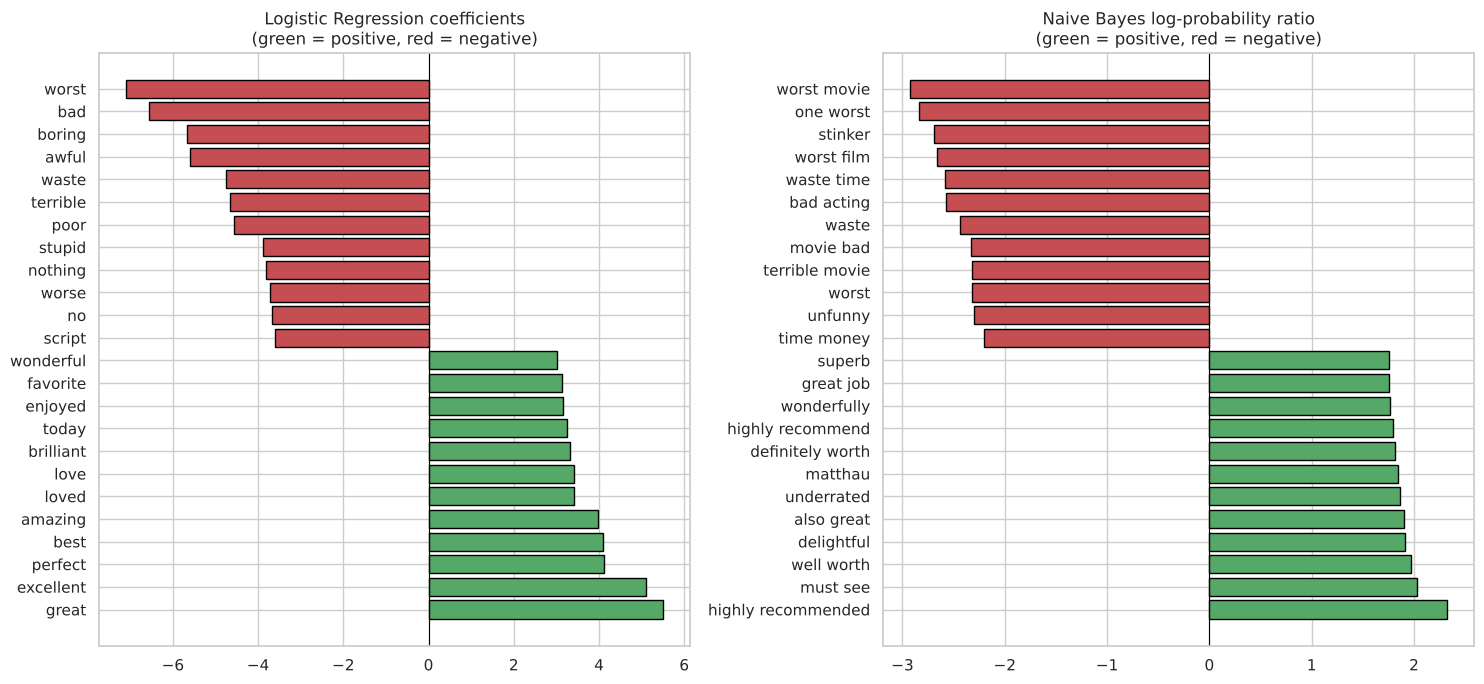

In [16]:
feature_names = vectorizer.get_feature_names_out()

# Logistic Regression: the sign and size of each coefficient
lr_coef = pd.Series(models["Logistic Regression"].coef_[0], index=feature_names)

# Naive Bayes: log-probability ratio of a word in positive vs. negative reviews
nb = models["Multinomial Naive Bayes"]
nb_ratio = pd.Series(nb.feature_log_prob_[1] - nb.feature_log_prob_[0], index=feature_names)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, (name, scores) in zip(axes, [("Logistic Regression coefficients", lr_coef),
                                     ("Naive Bayes log-probability ratio", nb_ratio)]):
    top = pd.concat([scores.nsmallest(12), scores.nlargest(12).iloc[::-1]]).iloc[::-1]
    ax.barh(top.index, top.values, color=["#55A868" if v > 0 else "#C44E52" for v in top.values], edgecolor="black")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{name}\n(green = positive, red = negative)")
plt.tight_layout()
plt.show()

Both models learn sensible vocabularies. Logistic Regression's strongest signals are single words: *great*,
*excellent* and *perfect* push towards positive, while *worst*, *bad*, *boring* and *awful* push towards negative.
Naive Bayes' most distinctive features are mostly **two-word phrases** such as *highly recommended*, *must see*,
*worst movie* and *waste time*, which shows the value of `ngram_range=(1, 2)`.

## 9. `predict_sentiment()`: test your own sentences

The helper applies exactly the same cleaning and TF-IDF transformation as during training, then returns the
predicted label and the model's confidence.

In [17]:
def predict_sentiment(text: str, model_name: str = "Logistic Regression") -> dict:
    """Classify a piece of text as positive or negative.

    Parameters
    ----------
    text : str
        Any review or sentence.
    model_name : str
        "Logistic Regression" (default) or "Multinomial Naive Bayes".

    Returns
    -------
    dict with the predicted label and the probability of that label.
    """
    features = vectorizer.transform([clean_text(text)])
    proba_positive = models[model_name].predict_proba(features)[0, 1]
    label = "positive" if proba_positive >= 0.5 else "negative"
    confidence = proba_positive if label == "positive" else 1 - proba_positive
    return {"label": label, "confidence": round(float(confidence), 4)}


print(predict_sentiment("This movie was absolutely wonderful, I loved every minute of it!"))

{'label': 'positive', 'confidence': 0.8416}


In [18]:
custom_phrases = [
    "An absolute masterpiece with brilliant acting and a beautiful soundtrack.",
    "Worst film I have seen in years. A complete waste of time and money.",
    "The plot was predictable and boring, but the actors did their best.",
    "I was not disappointed at all, it was even better than the book.",
    "Not good. Not bad. Just painfully average.",
    "My kids loved it and we will definitely watch it again!",
    "The special effects were great, but the story made no sense and I fell asleep.",
    "Highly recommended, one of the best movies of the decade.",
]

rows = []
for phrase in custom_phrases:
    lr = predict_sentiment(phrase, "Logistic Regression")
    nb_ = predict_sentiment(phrase, "Multinomial Naive Bayes")
    rows.append({"Text": phrase,
                 "Logistic Regression": f"{lr['label']} ({lr['confidence']:.0%})",
                 "Naive Bayes": f"{nb_['label']} ({nb_['confidence']:.0%})"})

pd.set_option("display.max_colwidth", 90)
pd.DataFrame(rows)

,Text,Logistic Regression,Naive Bayes
0,An absolute masterpiece with brilliant acting and a beautiful soundtrack.,positive (95%),positive (75%)
1,Worst film I have seen in years. A complete waste of time and money.,negative (99%),negative (97%)
2,"The plot was predictable and boring, but the actors did their best.",negative (98%),negative (80%)
3,"I was not disappointed at all, it was even better than the book.",negative (70%),positive (67%)
4,Not good. Not bad. Just painfully average.,negative (95%),negative (86%)
5,My kids loved it and we will definitely watch it again!,positive (98%),positive (72%)
6,"The special effects were great, but the story made no sense and I fell asleep.",negative (69%),negative (77%)
7,"Highly recommended, one of the best movies of the decade.",positive (99%),positive (96%)


Clear-cut reviews are classified correctly by both models, usually with high confidence. The harder cases show the
limits of bag-of-words models, which see words and short phrases but not sentence structure:
- *"I was not disappointed at all..."* fools Logistic Regression, which reacts to the word *disappointed*;
  Naive Bayes gets it right, but with low confidence.
- Mixed reviews (*"the special effects were great, but..."*) are labelled negative with noticeably lower confidence.

### Interactive mode

Set `INTERACTIVE = True` and run the cell to type your own reviews (enter a blank line to stop).
It is off by default so the notebook can run top to bottom without waiting for input.

In [19]:
INTERACTIVE = False

if INTERACTIVE:
    while True:
        user_text = input("Enter a review (blank to quit): ").strip()
        if not user_text:
            break
        print("  ->", predict_sentiment(user_text))

## 10. Performance summary

In [20]:
summary = results.join(cv_results[["CV accuracy mean", "CV accuracy std"]])
print(summary.round(4).to_string())
best = summary["Accuracy"].idxmax()
print(f"\nBest test accuracy: {best} ({summary.loc[best, 'Accuracy']:.4f})")

                         Accuracy  Precision  Recall  F1-score  ROC-AUC  Train time (s)  CV accuracy mean  CV accuracy std
Model                                                                                                                     
Multinomial Naive Bayes    0.8620     0.8657  0.8570    0.8613   0.9414          0.0118            0.8557           0.0052
Logistic Regression        0.8938     0.8900  0.8985    0.8943   0.9617          0.0622            0.8821           0.0026

Best test accuracy: Logistic Regression (0.8938)


**Summary**
- 20,000 IMDB reviews were cleaned with regex and NLTK (HTML, URLs, punctuation and stopwords removed, negations
  kept, words lemmatised) and converted into a 5,000-feature TF-IDF matrix of words and two-word phrases.
- **Logistic Regression** is the more accurate model, and **Multinomial Naive Bayes** is a strong, extremely fast
  baseline a few points behind. Both have ROC-AUC well above 0.9, and their cross-validation accuracy matches the
  test accuracy, so the results are stable. Exact values are in the table above.
- The most informative words are intuitive (*excellent*, *perfect* vs. *worst*, *waste*), and `predict_sentiment()`
  classifies new, unseen sentences correctly when the sentiment is clear.

**Possible next steps**
- Tune `C`, `max_features` and the n-gram range with `GridSearchCV`.
- Train on all 50,000 reviews.
- Try transformer embeddings (e.g. a fine-tuned DistilBERT) to handle negation and mixed sentiment better.